# Best SP vs. Best SP

Single-region Quadrant Analysis and Feature Distribution comparison.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import mplhep as mh
mh.style.use("ATLAS")

from src.core.Plotting.Localization import PlotTranslator
from src.core.Validation.SingleRegionComparisonRunner import (
    ComparisonModelConfig,
    SingleRegionComparisonRunner,
)

print(f"Project root: {PROJECT_ROOT}")

Project root: /eos/home-i04/p/pmourafr/egamma_master


In [2]:
TARGET_ET: int = 1
TARGET_ETA: int = 1
REGION_KEY: str = f"et_{TARGET_ET}_eta_{TARGET_ETA}"
LANGUAGE: str = PlotTranslator.validate_language("pt")

COMPARE_SAME_MODEL: bool = False     # True: Model 1 vs Model 1 | False: Model 1 vs Model 2 (set False for Athena cut)
TARGET_PD_MODE: str = "athena"       # 'athena' or 'custom'
CUSTOM_TARGET_PD: float = 0.9424     # Used when TARGET_PD_MODE == 'custom'
WORKING_POINT: str = "loose"         # Athena WP: 'loose', 'medium', 'tight'

# Optional `method` per model: None (uses notebook mode), 'best_sp', 'hard_cut', 'pileup', or 'athena_cut'
MODEL_1 = ComparisonModelConfig(
    config_path=PROJECT_ROOT / "config/NeuralRinger/ModelV10_HighBatch_100Rings.yaml",
    results_path=PROJECT_ROOT / "results/config_nameModelV10_HighBatch_100Rings_id20261112210846",
    alias="Model V10 (100 Rings)",
)
# # MODEL_2 using Athena cut (requires COMPARE_SAME_MODEL = False):
# MODEL_2 = ComparisonModelConfig.athena_cut(working_point=WORKING_POINT)
# # Or compare against another neural model:
MODEL_2 = ComparisonModelConfig(
    config_path=PROJECT_ROOT / "config/NeuralRinger/ModelV10_HighBatch_50Rings.yaml",
    results_path=PROJECT_ROOT / "results/config_nameModelV10_HighBatch_50Rings_id20261115051346",
    alias="Model V10 (50 Rings)",
)

DATA_PATH: Path = PROJECT_ROOT / "data/consolidated"
MANIFEST_PATH: Path = MODEL_1.results_path.parent / "split_manifest.json"
PLOT_FORMAT: str = "pdf"
LOG_Y: bool = True

COMPARISON_MODE: str = "best_sp_vs_best_sp"
OUTPUT_BASE_DIR: Path = PROJECT_ROOT / "Plots"

FEATURES_TO_PLOT: list[str] = [
    "trig_L2_calo_et", "trig_L2_calo_eta", "trig_L2_calo_phi",
    "trig_L2_calo_e237", "trig_L2_calo_e277", "trig_L2_calo_fracs1",
    "trig_L2_calo_weta2", "trig_L2_calo_ehad1", "trig_L2_calo_emaxs1",
    "trig_L2_calo_e2tsts1", "trig_L2_calo_wstot", "Eratio",
]

In [3]:
runner = SingleRegionComparisonRunner(
    iet=TARGET_ET,
    ieta=TARGET_ETA,
    model1=MODEL_1,
    model2=MODEL_2,
    compare_same_model=COMPARE_SAME_MODEL,
    target_pd_mode=TARGET_PD_MODE,
    custom_target_pd=CUSTOM_TARGET_PD,
    working_point=WORKING_POINT,
    data_path=DATA_PATH,
    manifest_path=MANIFEST_PATH,
    language=LANGUAGE,
    plot_format=PLOT_FORMAT,
    log_y=LOG_Y,
)
OUTPUT_DIR: Path = runner.build_output_dir(OUTPUT_BASE_DIR, mode=COMPARISON_MODE)
TABLES_DIR: Path = OUTPUT_DIR / "Tables"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)
payload = runner.prepare(mode=COMPARISON_MODE, features_to_plot=FEATURES_TO_PLOT)
print(f"Output dir: {OUTPUT_DIR}")
print(f"Comparing: {payload.strategy1_name}  vs  {payload.strategy2_name} ({len(payload.test_labels):,} test events)")

Output dir: /eos/home-i04/p/pmourafr/egamma_master/Plots/Model_V10_100_Rings_vs_Model_V10_50_Rings/Comparison_best_sp_vs_best_sp_cross_et_1_eta_1
Comparing: Model V10 (100 Rings) [Best SP]  vs  Model V10 (50 Rings) [Best SP] (14,378 test events)


In [4]:
strategy_df, counts_df, saved_quad = runner.run_quadrant_analysis(payload, OUTPUT_DIR, TABLES_DIR)
display(strategy_df)
display(counts_df)
print(f"Saved {sum(len(v) for v in saved_quad.values())} quadrant plots under: {OUTPUT_DIR / 'Quadrant'}")

,Strategy,PD,PD_unc,PF,PF_unc,SP,SP_unc
0,Model V10 (100 Rings) [Best SP],0.802454,0.006300,0.135978,0.003364,0.832953,0.003609
1,Model V10 (50 Rings) [Best SP],0.813721,0.006161,0.152061,0.003524,0.830742,0.003568


,Quadrant,Count,Ratio
0,Both Correct,11853,82.44%
1,Only Model V10 (100 Rings) [Best SP] Correct,324,2.25%
2,Only Model V10 (50 Rings) [Best SP] Correct,202,1.40%
3,Both Wrong,1999,13.90%


Saved 20 quadrant plots under: /eos/home-i04/p/pmourafr/egamma_master/Plots/Model_V10_100_Rings_vs_Model_V10_50_Rings/Comparison_best_sp_vs_best_sp_cross_et_1_eta_1/Quadrant


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,JS Divergence,JS Uncertainty
0,trig_L2_calo_et,True Signal,Model V10 (100 Rings) [Best SP],Model V10 (100 Rings) [Best SP] vs True Signal,3994,3205,0.003474,0.001422
1,trig_L2_calo_et,True Signal,Model V10 (50 Rings) [Best SP],Model V10 (50 Rings) [Best SP] vs True Signal,3994,3250,0.003556,0.001477
2,trig_L2_calo_et,True Signal,Athena Cut (Loose),Athena Cut (Loose) vs True Signal,3994,3106,0.004515,0.001753
3,trig_L2_calo_eta,True Signal,Model V10 (100 Rings) [Best SP],Model V10 (100 Rings) [Best SP] vs True Signal,3994,3205,0.000213,0.000635
4,trig_L2_calo_eta,True Signal,Model V10 (50 Rings) [Best SP],Model V10 (50 Rings) [Best SP] vs True Signal,3994,3250,0.000209,0.000642
5,trig_L2_calo_eta,True Signal,Athena Cut (Loose),Athena Cut (Loose) vs True Signal,3994,3106,0.000936,0.000969
6,trig_L2_calo_phi,True Signal,Model V10 (100 Rings) [Best SP],Model V10 (100 Rings) [Best SP] vs True Signal,3994,3205,0.000433,0.000923
7,trig_L2_calo_phi,True Signal,Model V10 (50 Rings) [Best SP],Model V10 (50 Rings) [Best SP] vs True Signal,3994,3250,0.000316,0.000896
8,trig_L2_calo_phi,True Signal,Athena Cut (Loose),Athena Cut (Loose) vs True Signal,3994,3106,0.000688,0.001032
9,trig_L2_calo_e237,True Signal,Model V10 (100 Rings) [Best SP],Model V10 (100 Rings) [Best SP] vs True Signal,3994,3205,0.002239,0.001163


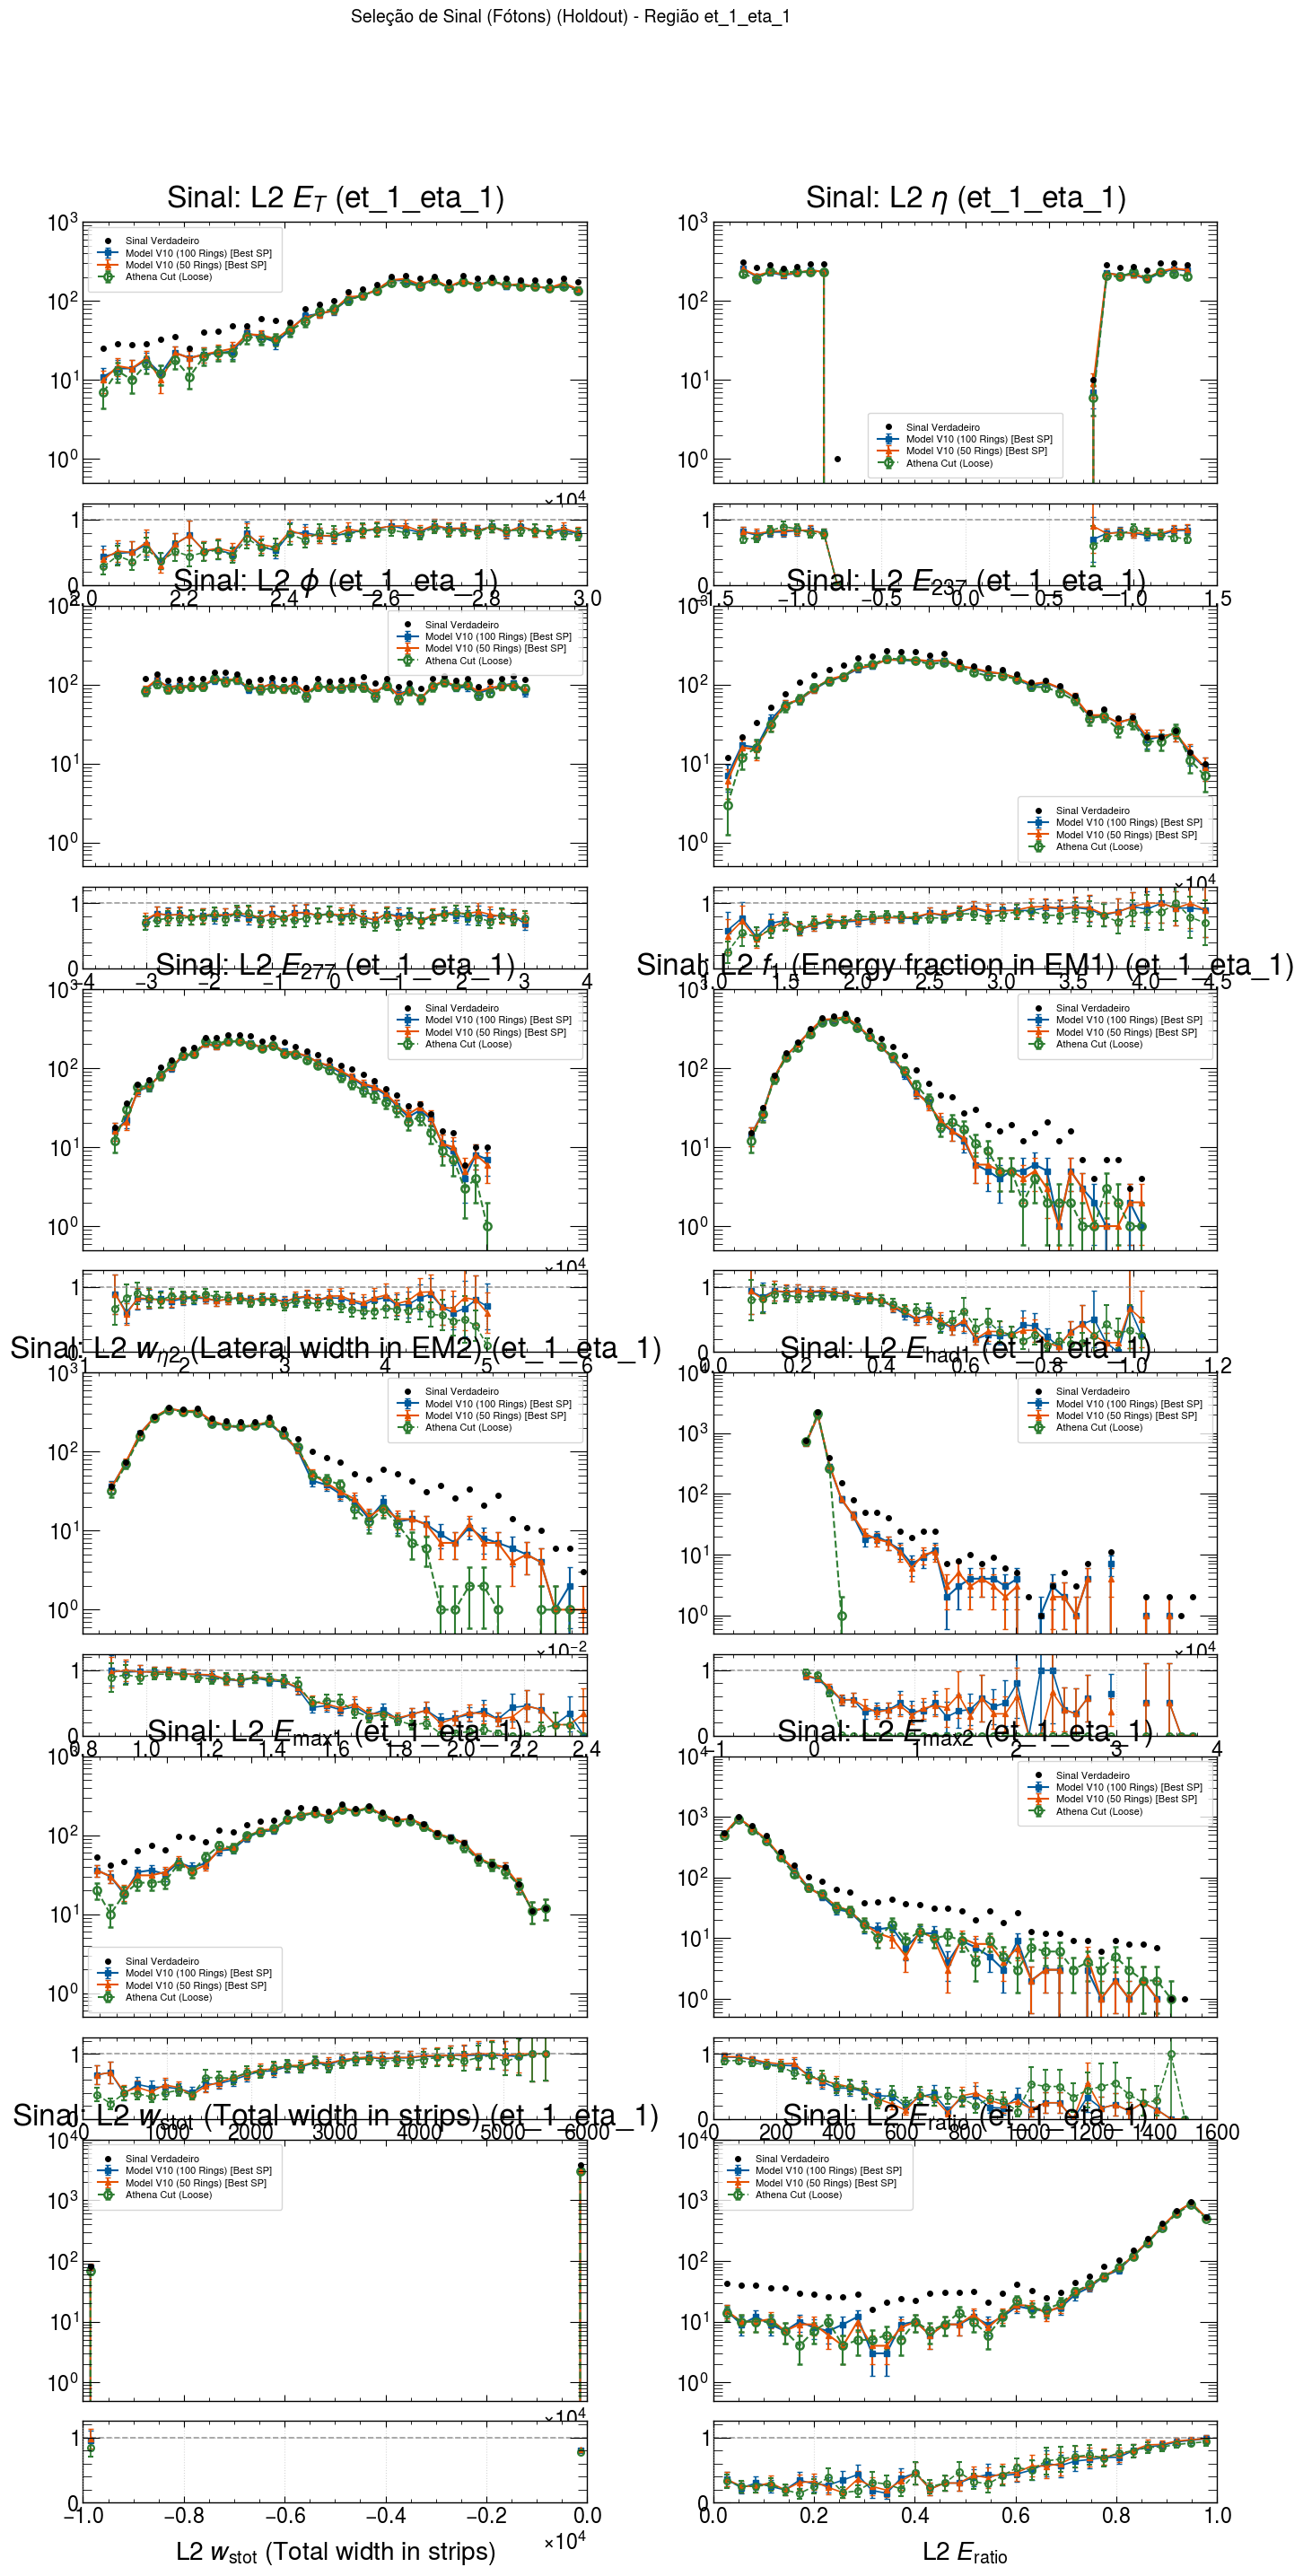

In [5]:
sig_js_df, fig_sig = runner.run_variable_analysis(payload, OUTPUT_DIR, TABLES_DIR, is_signal=True)
display(sig_js_df)

,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,JS Divergence,JS Uncertainty
0,trig_L2_calo_et,True Background,Model V10 (100 Rings) [Best SP],Model V10 (100 Rings) [Best SP] vs True Backgr...,10384,1412,0.006770,0.002490
1,trig_L2_calo_et,True Background,Model V10 (50 Rings) [Best SP],Model V10 (50 Rings) [Best SP] vs True Background,10384,1579,0.006156,0.002132
2,trig_L2_calo_et,True Background,Athena Cut (Loose),Athena Cut (Loose) vs True Background,10384,4309,0.002486,0.000915
3,trig_L2_calo_eta,True Background,Model V10 (100 Rings) [Best SP],Model V10 (100 Rings) [Best SP] vs True Backgr...,10384,1412,0.003620,0.001878
4,trig_L2_calo_eta,True Background,Model V10 (50 Rings) [Best SP],Model V10 (50 Rings) [Best SP] vs True Background,10384,1579,0.003832,0.001462
5,trig_L2_calo_eta,True Background,Athena Cut (Loose),Athena Cut (Loose) vs True Background,10384,4309,0.010992,0.001552
6,trig_L2_calo_phi,True Background,Model V10 (100 Rings) [Best SP],Model V10 (100 Rings) [Best SP] vs True Backgr...,10384,1412,0.004013,0.002050
7,trig_L2_calo_phi,True Background,Model V10 (50 Rings) [Best SP],Model V10 (50 Rings) [Best SP] vs True Background,10384,1579,0.003261,0.001666
8,trig_L2_calo_phi,True Background,Athena Cut (Loose),Athena Cut (Loose) vs True Background,10384,4309,0.001141,0.000769
9,trig_L2_calo_e237,True Background,Model V10 (100 Rings) [Best SP],Model V10 (100 Rings) [Best SP] vs True Backgr...,10384,1412,0.028317,0.004219


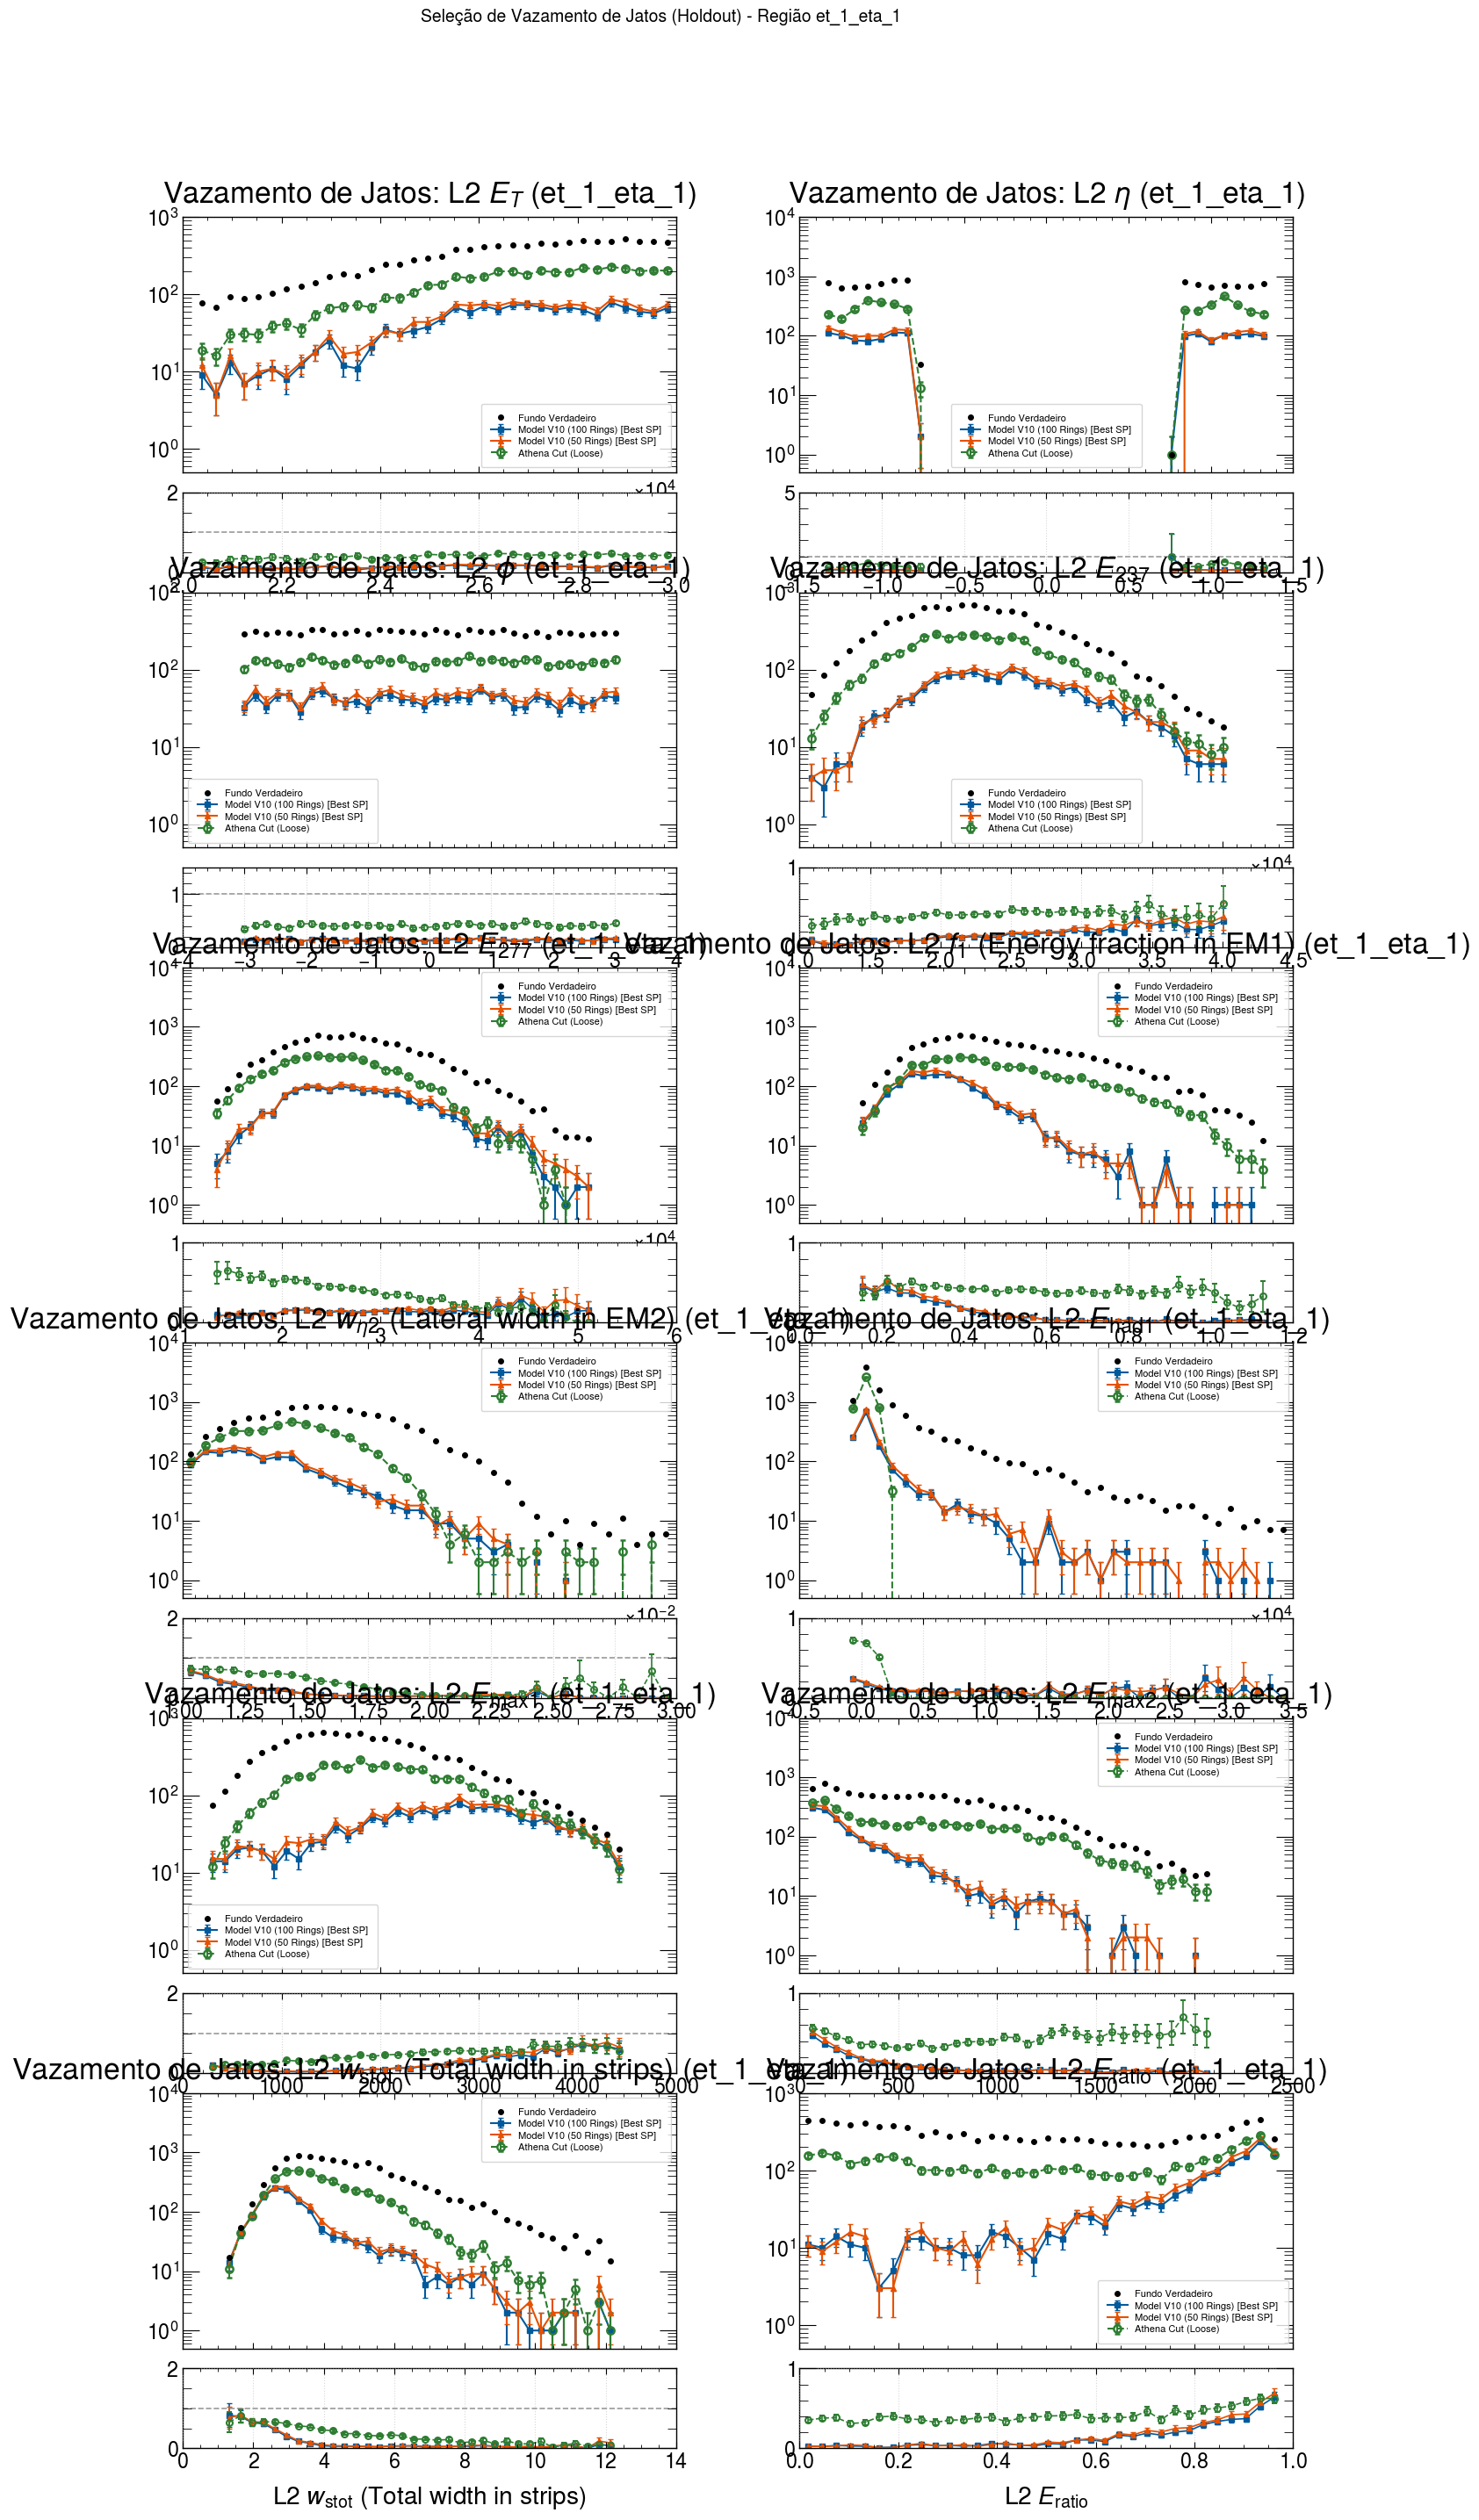

In [6]:
bg_js_df, fig_bg = runner.run_variable_analysis(payload, OUTPUT_DIR, TABLES_DIR, is_signal=False)
display(bg_js_df)